**Problem 1 (100 pts). Goal: estimate V(2) using MC and TD and compare convergence behavior**: Here is an example where boot-strapping (as used in TD(0)) could be helpful: we assume that the random walk always starts from state 0, and $\gamma = 1$. States: {0,1,2,3,4}; 4 terminal.
Rewards: only on transition 3→4, R ~ Bernoulli(0.5) (with a fair coin flip, sometimes you getreward of 1 and sometime 0. )

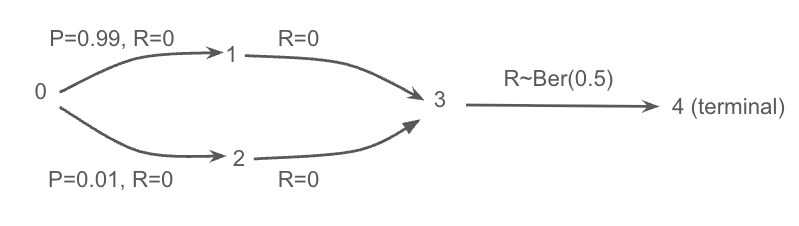

For this example, you will write a gymnasium environment, find the true state value with value iteration, then compare the value prediction of Monte Carlo (every visit) model, vs that from TD(0) model, for the state 2. The goal is to see if TD(0) is truely helful, and also see the difference between TD(0) with constant step size alpha, and with decaying step size

#### 1) (20pts) Write a  gymnasium environment for this example (ok to revise code in the lecture note. Please use the latest lecture note of Feb 24, 2026. The previous one has a small bug)

In [37]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from scipy.stats import bernoulli
class FiveStateEnv(gym.Env):
    def __init__(self, start_state = 0):
            self.agent_state = start_state
            self.action_space = [-1, 1] # down and up
            self.goal_states = {4}
            self.states = [0,1,2,3,4]
            self.gamma = 1.0
            self.start_state = start_state

    def policy(self, s): # return [[a, π(a|s)], ...] for all a in action space, where p is the probability of taking action a in state s
            if s == 0:
                return [[1,0.99],[-1,0.01]]
            elif s in (1,2,3):
                return [[1,1]]
 
            elif s in self.goal_states:
                 raise(ValueError(f"state {s} is terminal, no action to take"))
            else:
                raise(ValueError(f"no such state {s}"))

    def dynamics(self, s, a): #this calculates P(s', r|s, a), it return [[s', r, p],...]  
            if s in self.goal_states:
                return []
            elif s == 0 and a == 1:
                return [[1, 0, 1.0]]
            elif s == 0 and a == -1:
                return [[2, 0, 1.0]]
            elif s in (1, 2) and a == 1:
                return [[3, 0, 1.0]]
            elif s == 3 and a == 1:
                return [[4, 0, 0.5], [4, 1, 0.5]]   # R ~ Bernoulli(0.5)
            else:
                raise ValueError(f"invalid (state, action) = ({s}, {a})")

    def reset(self, options = {}): # return initial observation, info. Reset the start_state if options has "start_state"
            if "start_state" in options:
                self.start_state = options["start_state"]
            self.agent_state = self.start_state
            return self.agent_state, {}

    def sample_action(self, s): # return a sampled action according to the policy in state s
            pi = self.policy(s)
            actions = [x[0] for x in pi]
            probs = [x[1] for x in pi]
            return random.choices(actions, weights=probs, k=1)[0]

    def sample_state_reward(self, s, a): # given action, find the next state and reward based on dynamics
            res = self.dynamics(s, a) # [[s', r, p],...]
            states_rewards = [srp[:2] for srp in res]
            probs = [srp[-1] for srp in res]
            return random.choices(states_rewards, weights=probs, k=1)[0]

    def step(self, a): # return observation, reward, terminated, truncated, info
            s0 = self.agent_state
            [s1, reward] = self.sample_state_reward(s0, a) # sample s', r given s, a
            self.agent_state = s1
            done = self.agent_state in self.goal_states# True if self.agent_state in self.goal_states else False
            return self.agent_state, reward, done, False, {}

    def episode(self, start_state = None): # return an episode [(s, a, r, s'), ...]
            res = []
            if start_state is not None:
                self.reset(options={"start_state": start_state})
            state = self.start_state
            while True:
                action = self.sample_action(state)
                obs, reward, terminated, truncated, info = self.step(action)
                new_state = obs
                res.append((state, action, reward, new_state))
                state = new_state
                if terminated:
                    self.reset()
                    return res
            

#### 2) (10pts) Write the value iteration given the environment, and calculate the state values for states 0-4 (ok to reuse code in the lecture note)
- Assume a fixed policy shown in the diagram. Return the converged V.

In [38]:
#policy eval vis value iteration
def value_iteration(env: FiveStateEnv, gamma = 1.0, epsilon = 0.001, verbose = False, v_default = 0.):
    v = [v_default] * len(env.states)
    for s in env.goal_states:
        v[s] = 0.0 
    while True:
        diff = 0
        for s in env.states:
            if s in env.goal_states:
                continue
            v_new = 0
            for a,π_a in env.policy(s):
                q = 0
                for s2,reward,trans_prob in env.dynamics(s,a):
                    q += trans_prob * (reward + env.gamma * v[s2])
                v_new += π_a * q 
            diff = max(diff,abs(v_new - v[s]))
            v[s] = v_new
        if verbose:
            print(v, diff)
        if diff < epsilon:
                return v
   
env = FiveStateEnv()
value_iteration(env, verbose = True)

[0.0, 0.0, 0.0, 0.5, 0.0] 0.5
[0.0, 0.5, 0.5, 0.5, 0.0] 0.5
[0.5, 0.5, 0.5, 0.5, 0.0] 0.5
[0.5, 0.5, 0.5, 0.5, 0.0] 0


[0.5, 0.5, 0.5, 0.5, 0.0]

#### 3) (20pts) Write the TD0 algorithm for finding state value given an environment  (revise the code in lecture note is fine)
- the main difference between this code, and the one in the lecturenote, is that in addition to specifying alpha as a float, there is an option to specific alpha = 'auto'. 
- If `alpha = 'auto'`, keep a counter array N, and whenever a state s is seen, 
$$N[s]++$$
    - then define the step size as 
    $$alpha0 = 1/N[s]$$
    - TD0 update 
    $$v[s] = v[s] + alpha0*(r+gamma*v[s'] - v[s])$$
- In other words, when `alpha = 'auto'`, use per-state visit counts so each state has its own decreasing step size in order to satisfies the Robbins–Monro condition

In [39]:
def TD0_ValuePrediction(env, gamma = 1, alpha: float | str = 0.1, max_episode = 1000, seed = 123, v_default = 0.5):
    # alpha could be 'auto'
    random.seed(seed)
    # --------your code. v_t is a dictionary, v_t[s] gives the value of state s at episode 1,2,..., max_episode
    states = env.states
    v_t = {s:[] for s in states} # this is used to record progress of v(s) over time
    v = {s:v_default for s in states}
    N = {s:0 for s in states} 
    terminal_states = env.goal_states
    
    for s in states:
        if s in terminal_states:
            v[s] = 0.0 # terminal state much have 0 value
            
    for _ in range(max_episode):
        seq = env.episode(0) # seq = [(s, a, r, s'),...],for this environment, the start state is zero.
        for (s, a, r, s2) in seq:
            if alpha == 'auto':
                N[s] += 1
                alpha0 = 1/N[s]
            else:
                alpha0 = alpha

            v[s] = v[s] + alpha0 * (r + gamma*v[s2] - v[s])
        for s in states:
            v_t[s] = v_t[s] + [v[s]]
    return v, v_t
    


#### 4) (10pts) Write the MonteCarloValuePrediction code (using the code in lecture note is fine)


In [40]:
def MonteCarloValuePrediction(env, gamma = 1.0, first_visit = True, max_episode = 1000, seed = 123, 
                              incremental = False, alpha = None, v_default = 0.5):
    random.seed(seed)
    # --------your code. v_t is a dictionary, v_t[s] gives the value of state s at episode 1,2,..., max_episode
    total = {}; count = {}; v = {}; seq_len = 0; 
    states = env.states
    v_t = {s:[] for s in states} # this is used to record progress of v(s) over time
    v = {s:v_default for s in states}
    terminal_states = env.goal_states
    
    for s in states:
        if s in terminal_states:
            v[s] = 0.0 # terminal state much have 0 value
     
    for _ in range(max_episode):
        seq = env.episode(0) # seq = [(s, a, r, s'),...]
        G = 0
        
        if first_visit: # record first appearance position
            first = {}; pos = 0
            for (s, a, r, s2) in seq[::-1]:
                first[s] = pos
                pos = pos + 1
        
        pos = 0
        for (s, a, r, s2) in seq[::-1]:
            G = gamma*G + r
            if not first_visit or first[s] == pos:
                total[s] = total.get(s, 0.0) + G
                count[s] = count.get(s, 0) + 1
                v[s] = total[s]/count[s]
            pos = pos + 1

        for s in states:
            v_t[s] = v_t[s] + [v[s]]
    
    return v, v_t

#### 5) (40pts) Compare the state value of s=2 with MC and TD0. 
- Plot the v_mc[s] - v_truth[s] for s = 2 with v calculated by MC (every visit, no incremental update) using 1,2,3,...,1000 episodes
- Plot the v_td0[s] - v_truth[s] for s = 2 with v calculated by TD0 (alpha = 'auto') using 1,2,3,...,1000 episodes
- Plot the v_td0[s] - v_truth[s] for s = 2 with v calculated by TD0 (alpha = 0.05) using 1,2,3,...,1000 episodes
- Reflect on what you see 

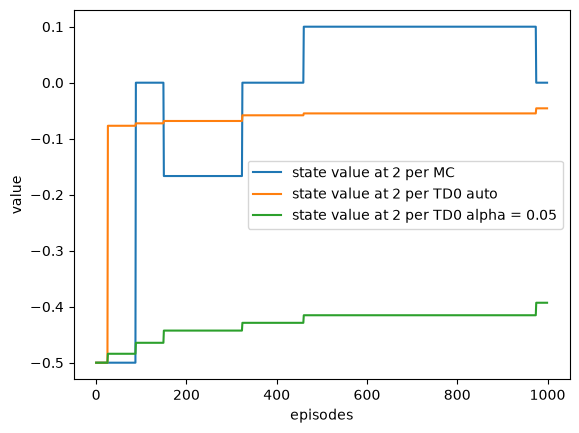

In [41]:
import matplotlib.pyplot as plt
env = FiveStateEnv()
episodes = 1000; alpha = 0.05
v_truth = value_iteration(env)
res_mc = MonteCarloValuePrediction(env, gamma = 1.0, first_visit = False, max_episode = episodes, seed = 123, 
                          incremental = False, alpha = None, v_default = 0.)[1]
res_td0_auto = TD0_ValuePrediction(env, gamma = 1, alpha = "auto", max_episode = episodes, seed = 123, v_default = 0.)[1]
res_td0_fixed = TD0_ValuePrediction(env, gamma = 1, alpha = alpha, max_episode = episodes, seed = 123, v_default = 0.)[1]

for s in range(2,3):
    plt.plot(np.array(res_mc[s])-v_truth[s], label = f"state value at {s} per MC")
    plt.plot(np.array(res_td0_auto[s])-v_truth[s], label = f"state value at {s} per TD0 auto")
    plt.plot(np.array(res_td0_fixed[s])-v_truth[s], label = f"state value at {s} per TD0 alpha = {0.05}")
plt.xlabel("episodes")
plt.ylabel("value")
plt.legend()

**Reflection.** All three curves only change at the same few episodes (about 6 steps in 1000 episodes), because the episode always starts at state 0 and state 2 is rarely visited (1% chance).

- **MC (every visit)** is noisy: its error jumps up and down between roughly −0.17 and +0.1 at each visit. Each visit only adds one 0-or-1 return, and with so few visits the average swings a lot. It ends near 0, but it moved away from 0 several times along the way, so this looks more like luck than convergence.
- **TD(0), α = 'auto'** is the most stable: at the very first visit it jumps from −0.5 to about −0.07, and then it creeps steadily toward 0. This works because TD updates v(2) toward r + v(3), and v(3) is visited in every episode, so it is already a good estimate. With α = 1/N, the first update takes that target almost completely.
- **TD(0), α = 0.05** moves in the right direction at every visit, but only by small steps, so after 1000 episodes it is still far off (around −0.4).

**Takeaway:** bootstrapping helps a rarely visited state, because it can borrow the value of a frequently visited next state instead of waiting for many of its own noisy returns. But the step size matters: a small constant α learns too slowly when visits are rare, while a decaying per-state step size (1/N) learns fast at first and still settles down.

In [46]:
! python -m jupyter nbconvert 07_Model_Free_Prediction_HW_TD0.ipynb --to webpdf

[NbConvertApp] Converting notebook 07_Model_Free_Prediction_HW_TD0.ipynb to webpdf
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Building PDF
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 232737 bytes to 07_Model_Free_Prediction_HW_TD0.pdf


In [45]:
! playwright install chromium

185.8 MiB [                    ] 0% 0.0s185.8 MiB [                    ] 0% 126.5s185.8 MiB [                    ] 0% 87.3s185.8 MiB [                    ] 0% 68.8s185.8 MiB [                    ] 0% 58.1s185.8 MiB [                    ] 0% 44.2s185.8 MiB [                    ] 0% 33.7s185.8 MiB [                    ] 0% 30.0s185.8 MiB [                    ] 0% 28.2s185.8 MiB [                    ] 0% 53.0s185.8 MiB [                    ] 0% 51.1s185.8 MiB [                    ] 0% 36.2s185.8 MiB [                    ] 1% 29.4s185.8 MiB [                    ] 1% 28.9s185.8 MiB [                    ] 1% 28.0s185.8 MiB [                    ] 1% 27.7s185.8 MiB [                    ] 1% 27.3s185.8 MiB [                    ] 1% 26.3s185.8 MiB [                    ] 1% 26.0s185.8 MiB [                    ] 1% 26.1s185.8 MiB [                    ] 1% 25.4s185.8 MiB [                    ] 1% 25.0s185.8 MiB [                    ] 1% 24.8s185.8 MiB [                    ] 2% 24.4s185.8 MiB [     